# Advanced Stage

Here is the final stage and we'll use some thing that we already done on intermediate stage so let's begin for it again.

Here the question to answer is : "Build the Digital Opportunity Index."

1. Load, rename, inner merge on country (same as Intermediate).

In [8]:
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import matplotlib.pyplot as ptl
import seaborn as sns

# LOAD

happiness_df = pd.read_csv("/home/mikes/ChallengeDT/datasource/World-happiness-report-2024.csv")
youtube_df = pd.read_csv("/home/mikes/ChallengeDT/datasource/youtube-users-by-country-2025.csv")

# RENAME

happiness_df = happiness_df.rename(columns= {
    "Country name" : "country",
    "Ladder score" : "happiness",
    "Log GDP per capita" : "log_gdp",
})

youtube_df = youtube_df.rename(columns={
    "YouTubeUsers_Penetration_Pct_2024Feb" : "penetration_2024",
    "YouTubeUsers_TotalUsers_Num_2024Feb" : "users_2024"
})

# MERGED

merged_df = pd.merge(youtube_df, happiness_df, on="country", how="inner")
print("inner join: ", len(merged_df))

advanced_df = merged_df.dropna(subset=["log_gdp"]).copy()
print("n after dropping missing log GDP: ", len(advanced_df))



inner join:  80
n after dropping missing log GDP:  79


Now we have prepare the "advance_df" to work on it. So let's move forward :D

In [13]:
# let's create the scaler

scaler = MinMaxScaler()

# let's fit and transform

scaled = scaler.fit_transform(advanced_df[["happiness", "log_gdp", "penetration_2024"]])

# let's put the array back into the DataFrame

advanced_df["happiness_norm"] = scaled[:, 0]
advanced_df["log_gdp_norm"] = scaled[:, 1]
advanced_df["penetration_norm"] = scaled[:, 2]

# Let's check the quality

print(advanced_df[["happiness_norm", "log_gdp_norm", "penetration_norm"]].describe())

# The index

advanced_df["opportunity_index"] = (advanced_df["happiness_norm"] + advanced_df["log_gdp_norm"] - advanced_df["penetration_norm"])


#Top 10 markets

top_ten = advanced_df.sort_values("opportunity_index", ascending=False).head(10)
print(top_ten[["country", "happiness", "log_gdp", "penetration_2024", "users_2024", "opportunity_index"]])

       happiness_norm  log_gdp_norm  penetration_norm
count       79.000000     79.000000         79.000000
mean         0.662480      0.536753          0.699722
std          0.198498      0.244029          0.206180
min          0.000000      0.000000          0.000000
25%          0.596544      0.344010          0.627660
50%          0.705205      0.584027          0.760284
75%          0.798967      0.740017          0.824113
max          1.000000      1.000000          1.000000
          country  happiness  log_gdp  penetration_2024  users_2024  \
79        Iceland      7.525    1.881              74.0      276000   
64        Ireland      6.838    2.129              79.8     4010000   
55        Denmark      7.583    1.908              80.5     4720000   
1   United States      6.725    1.939              72.2   239000000   
49    Switzerland      7.060    1.970              79.2     6920000   
59        Finland      7.741    1.844              82.2     4460000   
57         Norway

- Let's create a bubble chart

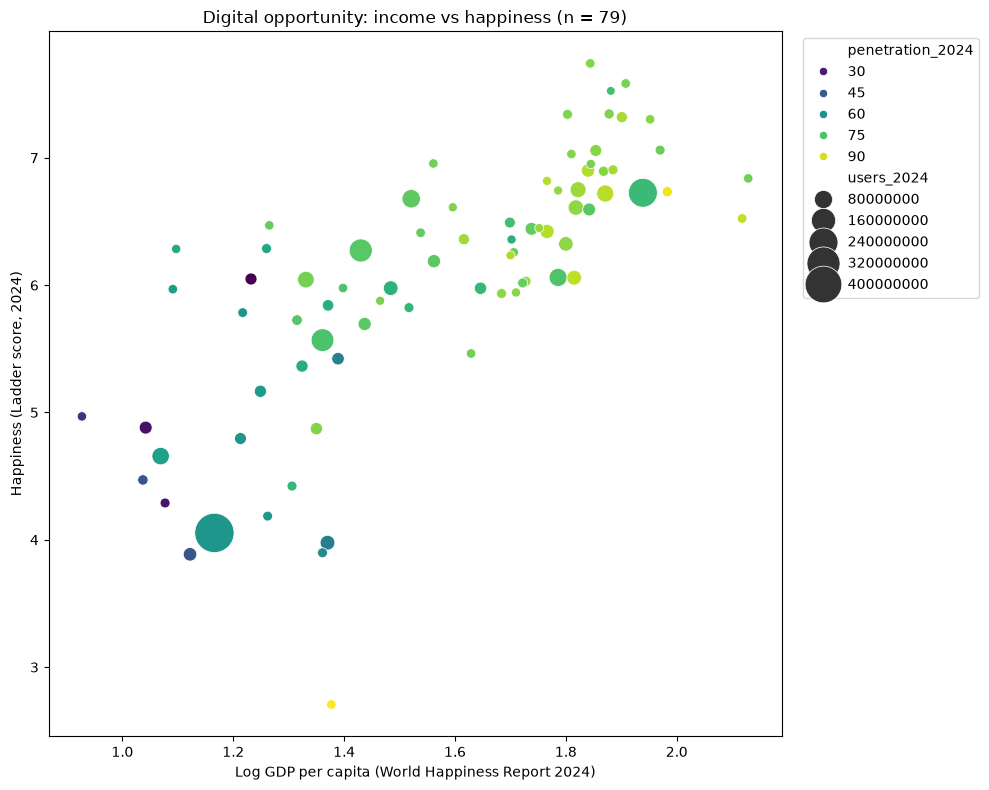

In [14]:
fig, ax = ptl.subplots(figsize=(10, 8))
sns.scatterplot(
    data=advanced_df,
    x="log_gdp",
    y="happiness",
    size="users_2024",
    hue="penetration_2024",
    sizes=(40, 800),
    ax=ax,
    palette="viridis",
)
ax.set_xlabel("Log GDP per capita (World Happiness Report 2024)")
ax.set_ylabel("Happiness (Ladder score, 2024)")
ax.set_title("Digital opportunity: income vs happiness (n = 79)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(Path("/home/mikes/ChallengeDT/outputs/figures/04_opportunity_bubbles.png"), dpi=150)
ptl.show()

## Conclusions (Advanced)

**Sample.** The Digital Opportunity Index is computed on the **inner join** of YouTube (February 2024) and the World Happiness Report 2024. After dropping **Bahrain** (missing log GDP per capita), **n = 79** countries. Min-Max scaling uses **this sample only**, so 0 and 1 mean lowest and highest **among these 79**, not a global theoretical maximum.

**Formula.**  
`opportunity_index = happiness_norm + log_gdp_norm − penetration_norm`  
Happiness and log GDP per capita are treated as **capacity**. YouTube penetration is **subtracted** so already saturated markets are penalised. User counts are **not** in the formula; they only set **bubble size**.

**Top 10 (table).** Most of the highest scores are **high-income, high-happiness** countries (for example Iceland, Ireland, Denmark, the United States, Switzerland, and other Nordic / Western European names). Their penetration is already **high** (often about 70–85%), but not always the sample maximum, so the penalty is not 1.0 and the two “capacity” terms still dominate. That is **not** the same as an empty YouTube market.

**Philippines** is the different case in the Top 10: mid-range happiness and log GDP, but **much lower penetration** (~24.5%). The index rises because the **minus term is small**. That is closer to the brief’s idea of **unused saturation**.

**How to read the bubble chart.**  
- **X (right):** higher log GDP per capita.  
- **Y (up):** higher Ladder (happiness) score.  
- **Size:** more YouTube users (audience volume). A large bubble is a big market, not a high index.  
- **Colour (yellow):** higher penetration (more saturated). Purple/teal is lower saturation.

The cloud slopes **up and to the right**: richer countries tend to be happier. They also tend to be **yellower** (already penetrated). **Opportunity** on this figure is therefore **upper-right but not fully yellow**. Bright yellow top-right = strong capacity, **crowded** YouTube. Large dark bubbles lower on the axes = huge audiences with less income/happiness.

**Limits.** The GDP input is **log GDP per capita**, not raw GDP. The index uses **equal weights** from the brief; it is not a causal model and does not prove that YouTube will grow if a country ranks high. Name mismatches excluded from the inner join (for example Taiwan / Czechia / Türkiye) are outside this ranking.

Let's save the top 10 markets in a csv

In [15]:
top_ten.to_csv("/home/mikes/ChallengeDT/outputs/tables/top10_opportunity.csv", index=False)